nov 21th

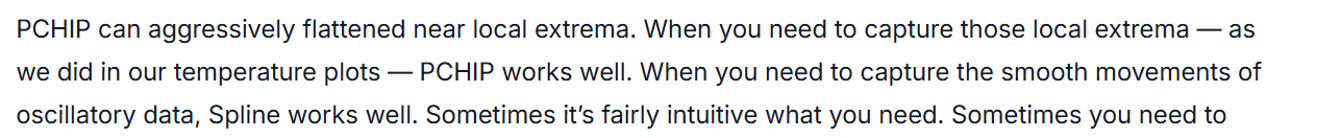

In [329]:
# import xarray as xr
# from scipy.interpolate import NearestNDInterpolator
from scipy.interpolate import griddata
from scipy.interpolate import PchipInterpolator, pchip_interpolate

import pandas as pd
import numpy as np
# from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

from pyproj import Transformer

### bringing in sed (TOS)

this will be the alpha dataset

In [330]:
dtos = pd.read_csv('..\\data\\mcs02\\TOS.csv', sep='\\s+', skiprows=1,
                 names=['x', 'y', 'z_sed'])

In [331]:
t = Transformer.from_crs('EPSG:32610', 'EPSG:4326', always_xy=True)
dtos['long'], dtos['lat'] = t.transform(dtos['x'].values, dtos['y'].values)

dtos = dtos[['x', 'y', 'lat', 'long', 'z_sed']]

print(dtos)

           x        y        lat        long     z_sed
0     193122  5277091  47.574574 -127.080768  3.387986
1     193116  5277093  47.574589 -127.080848  3.387924
2     193110  5277095  47.574604 -127.080929  3.387768
3     193104  5277097  47.574619 -127.081010  3.387614
4     193098  5277099  47.574634 -127.081091  3.387520
...      ...      ...        ...         ...       ...
8138  145323  5294476  47.706130 -127.728387  3.572323
8139  145317  5294478  47.706145 -127.728468  3.572380
8140  145311  5294480  47.706159 -127.728550  3.572307
8141  145305  5294482  47.706174 -127.728631  3.572182
8142  145299  5294485  47.706198 -127.728713  3.572203

[8143 rows x 5 columns]


### bringing in crust (TOC)

this will be the omega dataset

In [332]:
dtoc = pd.read_csv('..\\data\\mcs02\\TOC.csv', sep='\\s+', skiprows=1, 
                 names=['x', 'y', 'z_crust'])

ms --> s

In [333]:
t = Transformer.from_crs('EPSG:32610', 'EPSG:4326', always_xy=True)
dtoc['long'], dtoc['lat'] = t.transform(dtoc['x'].values, dtoc['y'].values)

dtoc = dtoc[['x', 'y', 'lat', 'long', 'z_crust']]

print(dtoc)

           x        y        lat        long   z_crust
0     193122  5277091  47.574574 -127.080768  4.506494
1     193116  5277093  47.574589 -127.080848  4.508189
2     193110  5277095  47.574604 -127.080929  4.510482
3     193104  5277097  47.574619 -127.081010  4.516385
4     193098  5277099  47.574634 -127.081091  4.525014
...      ...      ...        ...         ...       ...
8138  141816  5295751  47.715629 -127.776021  3.860610
8139  141810  5295754  47.715652 -127.776103  3.859799
8140  141804  5295756  47.715667 -127.776184  3.859563
8141  141798  5295758  47.715682 -127.776265  3.859924
8142  141793  5295760  47.715697 -127.776334  3.859273

[8143 rows x 5 columns]


c=x, s=z

In [334]:
# converting directions to numpy array (replacement to .values)

c_xy = dtoc[['x','y']].to_numpy()
s_xy = dtos[['x','y']].to_numpy()

In [335]:
print(f'c_xy:\n{c_xy[0:5]}')
print(f's_xy:\n{s_xy[0:5]}')

c_xy:
[[ 193122 5277091]
 [ 193116 5277093]
 [ 193110 5277095]
 [ 193104 5277097]
 [ 193098 5277099]]
s_xy:
[[ 193122 5277091]
 [ 193116 5277093]
 [ 193110 5277095]
 [ 193104 5277097]
 [ 193098 5277099]]


In [336]:
# normalizes a 2D vector into unit vectors with a length of 1
origin=c_xy[0]
d_c = c_xy[-1] - c_xy[0]
d_c = d_c / np.hypot(*d_c)

# distance along the line for both datasets

c_dis = (c_xy - c_xy[0]) @ d_c

In [337]:
d_s = s_xy[-1] - s_xy[0]
d_s = d_s / np.hypot(*d_s)

s_dis = (s_xy - s_xy[0]) @ d_s

In [338]:
# now converting crust depths to numpy array
c_z = dtoc['z_crust'].to_numpy()

In [339]:
order = np.argsort(c_dis)  # indices that sorts c from smallest to largest
c_dis, c_z = c_dis[order], c_z[order]

ensures original values are increasing and duplicates are removed (required for interp)

In [340]:
c_dis, idx = np.unique(c_dis, return_index=True)
c_z = c_z[idx]

In [341]:
print(f'min: {c_z.min()}, max: {c_z.max()}')

min: 3.859273, max: 4.656549


now we build the interpolator and evaluate at every sediment position

[pchipinterp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.PchipInterpolator.html#scipy.interpolate.PchipInterpolator)

from claude: "we fit one continuous curve through all the crust points, then reads that curve at each sediment distance (s_dis is a list of distances where you want a crust depth)"

In [342]:
interp_crust = pchip_interpolate(c_dis, c_z, s_dis)

making any values outside the range as NaNs

In [343]:
P = PchipInterpolator(c_dis, c_z, extrapolate=False)
interp_crust = P(s_dis)

In [344]:
dtos['z_crust'] = interp_crust

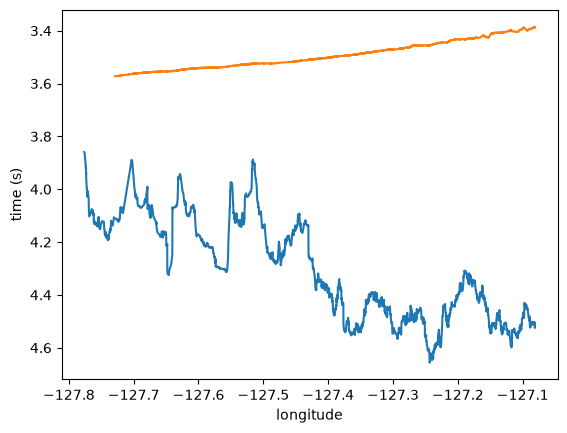

In [345]:
plt.plot(dtoc['long'], dtoc['z_crust'])
plt.plot(dtos['long'], dtos['z_sed'])
plt.gca().invert_yaxis()
plt.gca().set_ylabel('time (s)')
plt.gca().set_xlabel('longitude')
plt.show()

In [346]:
# building a new dataframe

df = pd.DataFrame({
    'x': dtos['x'],
    'y': dtos['y'],
    'long': dtos['long'],
    'lat': dtos['lat'],
    'z_sed': dtos['z_sed'],
    'z_crust': dtoc['z_crust']})

In [347]:
mask = (s_dis >= c_dis.min()) & (s_dis <= c_dis.max())

df['x'] = df['x'][mask]
df['y'] = df['y'][mask]
df['long'] = df['long'][mask]
df['lat'] = df['lat'][mask]
df['z_sed'] = df['z_sed'][mask]

df = df.dropna(how='all').reset_index(drop=True)

In [348]:
print(df.head())

        x        y        long        lat     z_sed   z_crust
0  193122  5277091 -127.080768  47.574574  3.387986  4.506494
1  193116  5277093 -127.080848  47.574589  3.387924  4.508189
2  193110  5277095 -127.080929  47.574604  3.387768  4.510482
3  193104  5277097 -127.081010  47.574619  3.387614  4.516385
4  193098  5277099 -127.081091  47.574634  3.387520  4.525014


time to depth

In [349]:
v_crust = 5910 # m/s
v_sed = 2000 # m/s
v_wat = 1500 # m/s

df['toc_m'] = (v_wat * (df['z_sed'] / 2) + (v_sed * (df['z_crust'] - df['z_sed']) / 2)).to_numpy()

df['tos_m'] = v_wat * (df['z_sed'] / 2)

In [350]:
print(df.head())

        x        y        long        lat     z_sed   z_crust      toc_m  \
0  193122  5277091 -127.080768  47.574574  3.387986  4.506494  3659.4975   
1  193116  5277093 -127.080848  47.574589  3.387924  4.508189  3661.2080   
2  193110  5277095 -127.080929  47.574604  3.387768  4.510482  3663.5400   
3  193104  5277097 -127.081010  47.574619  3.387614  4.516385  3669.4815   
4  193098  5277099 -127.081091  47.574634  3.387520  4.525014  3678.1340   

       tos_m  
0  2540.9895  
1  2540.9430  
2  2540.8260  
3  2540.7105  
4  2540.6400  


### downloading no grav...

In [351]:
# df.to_csv('..\\created_data\\mcs\\nov23_toc_tos_interp.csv', index=False)

# adding grav

In [352]:
dg = pd.read_csv("..\\created_data\\FA.csv", header=None, skiprows=1, names=['long', 'lat', 'FA'])
print(dg)

             long        lat          FA
0     -133.000003  37.983334  -20.522749
1     -133.000003  38.100001  -24.824638
2     -133.000003  38.216667  -31.192137
3     -133.000003  38.333334  -38.186611
4     -133.000003  38.450001  -32.169643
...           ...        ...         ...
16693 -119.000003  53.500001  111.308601
16694 -119.000003  53.616668   50.057011
16695 -119.000003  53.733334   37.020630
16696 -119.000003  53.850001    4.265869
16697 -119.000003  53.966668  -10.105060

[16698 rows x 3 columns]


"This code takes free-air gravity (FA) measured at one set of locations (dg) and estimates what it would be at a different set of locations (df, your profile points)"

In [353]:
df['FA'] = griddata((dg[['long','lat']].values), dg['FA'].values, df[['long','lat']].values, method='linear')

In [360]:
print(df.isna().sum())        
print(df)

x          0
y          0
long       0
lat        0
z_sed      0
z_crust    0
toc_m      0
tos_m      0
FA         0
dtype: int64
           x        y        long        lat     z_sed   z_crust       toc_m  \
0     193122  5277091 -127.080768  47.574574  3.387986  4.506494  3659.49750   
1     193116  5277093 -127.080848  47.574589  3.387924  4.508189  3661.20800   
2     193110  5277095 -127.080929  47.574604  3.387768  4.510482  3663.54000   
3     193104  5277097 -127.081010  47.574619  3.387614  4.516385  3669.48150   
4     193098  5277099 -127.081091  47.574634  3.387520  4.525014  3678.13400   
...      ...      ...         ...        ...       ...       ...         ...   
8138  145323  5294476 -127.728387  47.706130  3.572323  3.860610  2967.52925   
8139  145317  5294478 -127.728468  47.706145  3.572380  3.859799  2966.70400   
8140  145311  5294480 -127.728550  47.706159  3.572307  3.859563  2966.48625   
8141  145305  5294482 -127.728631  47.706174  3.572182  3.859924  2966

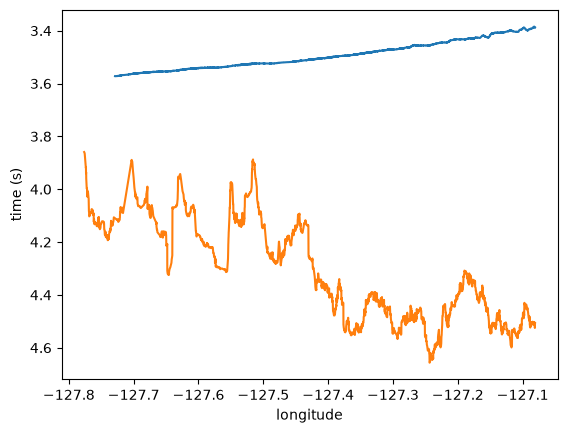

In [355]:
plt.plot(dtos['long'], dtos['z_sed'])
plt.plot(dtoc['long'], dtoc['z_crust'])
plt.gca().invert_yaxis()
plt.gca().set_ylabel('time (s)')
plt.gca().set_xlabel('longitude')
plt.show()

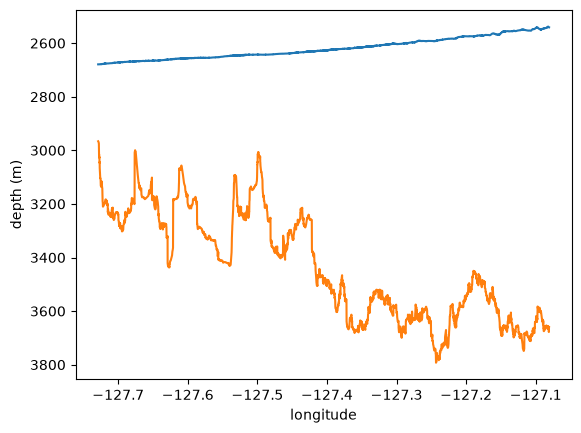

In [356]:
plt.plot(df['long'], df['tos_m'])
plt.plot(df['long'], df['toc_m'])
plt.gca().invert_yaxis()
plt.gca().set_ylabel('depth (m)')
plt.gca().set_xlabel('longitude')
plt.show()

### downloading w grav...

In [357]:
df.to_csv('..\\created_data\\mcs\\02_nov26_FA_toc_tos_interp.csv', index=False)